In [9]:
from nnfs.datasets import spiral_data
import numpy as np
import nnfs

x , y = spiral_data(samples=100 , classes=3)


In [10]:
class Layer_Dense :
    def __init__(self , n_inputs , n_neurons):
        self.weights = 0.01 * np.random.randn(n_neurons , n_inputs)
        self.biases = np.zeros((1 , n_neurons))
    
    def forward(self , inputs):
        self.inputs = inputs
        self.output = np.dot(inputs , self.weights.T) + self.biases

    def backward(self , dvalues):
        self.dweights = np.dot(self.inputs.T , dvalues)
        self.dbiases = np.sum(dvalues , axis= 0 , keepdims=True)
        self.dinputs = np.dot(dvalues, self.weights)  

In [11]:
class Activation_Relu:
    def forward(self , inputs):
        self.inputs = inputs
        self.output = np.maximum(0 , inputs)

    def backward(self , dvalues):
        self.dinputs = dvalues.copy()

        self.dinputs[self.inputs <= 0] = 0 

In [12]:
class Activation_Softmax:

    def forward(self , inputs):
        exp_values = np.exp(inputs - np.max(inputs , axis=1 , keepdims=True))

        probabilities = exp_values /np.sum(exp_values , axis=1 , keepdims = True)
        self.output = probabilities
       

In [13]:
class Loss:
    def calculate(self, y_pred, y_true):
        sample_losses = self.forward(y_pred, y_true)
        return np.mean(sample_losses)


class Loss_CategoricalCrossentropy(Loss):

    def forward(self , y_pred , y_true):

        if len(y_true.shape) == 1:
            confidences = y_pred[range(len(y_pred)) , y_true]
        else:
            confidences = np.sum(y_pred * y_true , axis = 1)

        return -np.log(confidences)     

    def backward(self , dvalues , y_true):
        samples = len(dvalues)
        labels = len(dvalues[0])

        if len(y_true.shape) == 1:
            y_true = np.eye(labels)[y_true]

        self.dinputs = -y_true/dvalues

        self.dinputs = self.dinputs/samples
                 

In [14]:
class Activation_Softmax_Loss_CategoricalCrossentropy:
    def __init__(self):
        self.activation = Activation_Softmax()
        self.loss = Loss_CategoricalCrossentropy()

    def forward(self , inputs , y_true):
        self.activation.forward(inputs)

        self.output = self.activation.output

        return self.loss.calculate(self.output , y_true)
    
    def backward(self , dvalues , y_true):
        samples = len(dvalues)

        if(len(y_true.shape) == 2):
            y_true = np.argmax(y_true , axis=1)
        
        self.dinputs = dvalues.copy()

        self.dinputs[range(samples) , y_true] -= 1

        self.dinputs = self.dinputs / samples

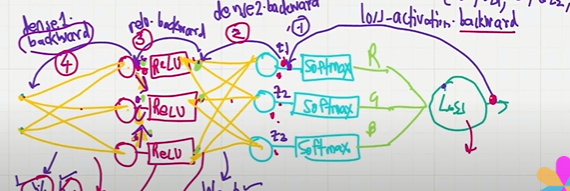

will implement this now

In [15]:
softmax_outputs = np.array([[0.7, 0.1, 0.2],
                            [0.1, 0.5, 0.4],
                            [0.02, 0.9, 0.08]])
class_targets = np.array([0, 1, 1])
softmax_loss = Activation_Softmax_Loss_CategoricalCrossentropy()
softmax_loss.backward(softmax_outputs, class_targets)
dvalues1 = softmax_loss.dinputs
print("Gradients: combined loss and activation:")
print(dvalues1)

# Create network
dense1 = Layer_Dense(2, 3)
activation1 = Activation_Relu()
dense2 = Layer_Dense(3, 3)
loss_activation = Activation_Softmax_Loss_CategoricalCrossentropy()

# Forward pass
dense1.forward(x)
activation1.forward(dense1.output)
dense2.forward(activation1.output)
loss = loss_activation.forward(dense2.output, y)

print(f"Loss: {loss}")

# Backward pass (corrected)
loss_activation.backward(loss_activation.output, y)
dense2.backward(loss_activation.dinputs)
activation1.backward(dense2.dinputs)  # Fixed: use dinputs instead of inputs
dense1.backward(activation1.dinputs)

print("Dense1 weights shape:", dense1.weights.shape)
print("Dense1 dweights shape:", dense1.dweights.shape)
print("Dense2 weights shape:", dense2.weights.shape)
print("Dense2 dweights shape:", dense2.dweights.shape)


Gradients: combined loss and activation:
[[-0.1         0.03333333  0.06666667]
 [ 0.03333333 -0.16666667  0.13333333]
 [ 0.00666667 -0.03333333  0.02666667]]
Loss: 1.0986123763993934
Dense1 weights shape: (3, 2)
Dense1 dweights shape: (2, 3)
Dense2 weights shape: (3, 3)
Dense2 dweights shape: (3, 3)


In [16]:
# Every layer's backward method:

# Takes dvalues as input (gradients flowing from the next layer)
# Computes self.dinputs as output (gradients to pass to the previous layer)

#  dinputs is always the output from a backward function.

In [17]:
# So dinputs is:
# Output of the current layer's backward function
# Input to the previous layer's backward function

In [18]:
# def backward(self, dvalues):  # dvalues = dL/dz (from next layer) 
#     self.dweights = np.dot(self.inputs.T, dvalues)  # dL/dW
#     self.dbiases = np.sum(dvalues, axis=0, keepdims=True)  # dL/db
#     self.dinputs = np.dot(dvalues, self.weights)  # dL/da_prev (previous layer's activation)

In [19]:
from nnfs.datasets import spiral_data
import numpy as np
import nnfs

x, y = spiral_data(samples=100, classes=3)

class Layer_Dense:
    def __init__(self, n_inputs, n_neurons):
        self.weights = 0.01 * np.random.randn(n_neurons, n_inputs)  # Your original shape
        self.biases = np.zeros((1, n_neurons))
    
    def forward(self, inputs):
        self.inputs = inputs
        self.output = np.dot(inputs, self.weights.T) + self.biases  # Transpose in forward pass
    
    def backward(self, grad_from_next_layer):  # grad_from_next_layer = dL/dz (gradient wrt pre-activation)
        # Gradients on parameters
        self.grad_weights = np.dot(self.inputs.T, grad_from_next_layer)  # dL/dW
        self.grad_biases = np.sum(grad_from_next_layer, axis=0, keepdims=True)  # dL/db
        # Gradients to pass to previous layer
        self.grad_to_prev_layer = np.dot(grad_from_next_layer, self.weights)  # dL/da_prev (gradient wrt previous layer's activation)

class Activation_Relu:
    def forward(self, inputs):
        self.inputs = inputs
        self.output = np.maximum(0, inputs)
    
    def backward(self, grad_from_next_layer):  # grad_from_next_layer = dL/da (gradient wrt ReLU's output/activation)
        self.grad_to_prev_layer = grad_from_next_layer.copy()  # dL/dz = dL/da * da/dz
        self.grad_to_prev_layer[self.inputs <= 0] = 0  # ReLU derivative: da/dz = 0 if z ≤ 0, 1 if z > 0

class Activation_Softmax:
    def forward(self, inputs):
        exp_values = np.exp(inputs - np.max(inputs, axis=1, keepdims=True))
        probabilities = exp_values / np.sum(exp_values, axis=1, keepdims=True)
        self.output = probabilities
    
  

class Loss:
    def calculate(self, y_pred, y_true):
        sample_losses = self.forward(y_pred, y_true)
        return np.mean(sample_losses)

class Loss_CategoricalCrossentropy(Loss):
    def forward(self, y_pred, y_true):
        samples = len(y_pred)
        # Clip data to prevent division by 0
        y_pred_clipped = np.clip(y_pred, 1e-7, 1 - 1e-7)
        
        if len(y_true.shape) == 1:
            correct_confidences = y_pred_clipped[range(samples), y_true]
        elif len(y_true.shape) == 2:
            correct_confidences = np.sum(y_pred_clipped * y_true, axis=1)
        
        negative_log_likelihoods = -np.log(correct_confidences)
        return negative_log_likelihoods
    
    def backward(self, predictions, y_true):
        samples = len(predictions)
        labels = len(predictions[0])
        
        if len(y_true.shape) == 1:
            y_true = np.eye(labels)[y_true]
        
        self.grad_to_prev_layer = -y_true / predictions
        self.grad_to_prev_layer = self.grad_to_prev_layer / samples

class Activation_Softmax_Loss_CategoricalCrossentropy:
    def __init__(self):
        self.activation = Activation_Softmax()
        self.loss = Loss_CategoricalCrossentropy()
    
    def forward(self, inputs, y_true):
        self.activation.forward(inputs)
        self.output = self.activation.output
        return self.loss.calculate(self.output, y_true)
    
    def backward(self, predictions, y_true):
        samples = len(predictions)
        
        if len(y_true.shape) == 2:
            y_true = np.argmax(y_true, axis=1)
        
        self.grad_to_prev_layer = predictions.copy()
        self.grad_to_prev_layer[range(samples), y_true] -= 1
        self.grad_to_prev_layer = self.grad_to_prev_layer / samples

# Test the implementation
softmax_outputs = np.array([[0.7, 0.1, 0.2],
                            [0.1, 0.5, 0.4],
                            [0.02, 0.9, 0.08]])
class_targets = np.array([0, 1, 1])
softmax_loss = Activation_Softmax_Loss_CategoricalCrossentropy()
softmax_loss.backward(softmax_outputs, class_targets)
gradient_output = softmax_loss.grad_to_prev_layer
print("Gradients: combined loss and activation:")
print(gradient_output)

# Create network
dense1 = Layer_Dense(2, 3)
activation1 = Activation_Relu()
dense2 = Layer_Dense(3, 3)
loss_activation = Activation_Softmax_Loss_CategoricalCrossentropy()

# Forward pass
dense1.forward(x)
activation1.forward(dense1.output)
dense2.forward(activation1.output)
loss = loss_activation.forward(dense2.output, y)

print(f"Loss: {loss}")

# Backward pass (with clearer variable names)
loss_activation.backward(loss_activation.output, y)
dense2.backward(loss_activation.grad_to_prev_layer)
activation1.backward(dense2.grad_to_prev_layer)
dense1.backward(activation1.grad_to_prev_layer)

print("Dense1 weights shape:", dense1.weights.shape)
print("Dense1 weight gradients shape:", dense1.grad_weights.shape)
print("Dense2 weights shape:", dense2.weights.shape)
print("Dense2 weight gradients shape:", dense2.grad_weights.shape)

# Example of how to update weights (basic gradient descent)
learning_rate = 0.1
dense1.weights -= learning_rate * dense1.grad_weights.T  # Note: transpose needed for weight update
dense1.biases -= learning_rate * dense1.grad_biases
dense2.weights -= learning_rate * dense2.grad_weights.T  # Note: transpose needed for weight update
dense2.biases -= learning_rate * dense2.grad_biases

Gradients: combined loss and activation:
[[-0.1         0.03333333  0.06666667]
 [ 0.03333333 -0.16666667  0.13333333]
 [ 0.00666667 -0.03333333  0.02666667]]
Loss: 1.0986187800152003
Dense1 weights shape: (3, 2)
Dense1 weight gradients shape: (2, 3)
Dense2 weights shape: (3, 3)
Dense2 weight gradients shape: (3, 3)


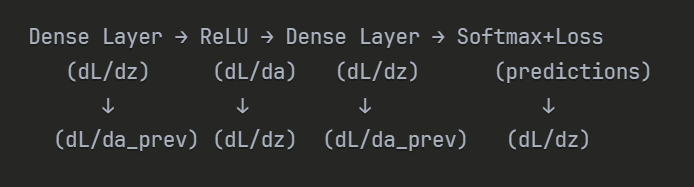

In [ ]:
class Optimizer_GD:

    def __init__(self , learning_rate = 1):
        self.learning_rate = learning_rate

    def update_params(self , layer):    
     layer.weights = layer.weights - self.learning_rate * layer.dweights
     layer.biases = layer.biases - self.learning_rate * layer.dbiases


In [21]:
# # class Car:
# #     def __init__(self, brand):
# #         self.brand = brand

# # my_car = Car("Tesla")
# # print(my_car.brand)  # Tesla

# # init is the constructor , needs to assign members of class when a object is created
# in puthon u can dynamically create memebers of class using self. no need to define them earlier like in java

In [22]:
# issue with this is , u can miss the global minima if step size is too small or else u wont even reach global minima if step size is too big

In [23]:
# we will use this 

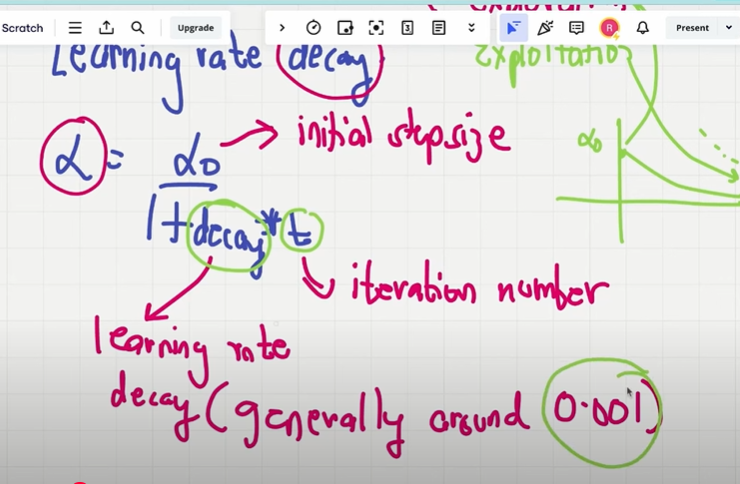

In [25]:
# as iterations increases step size will become smalller and initally step size is comparatively larger.

In [27]:
class Optimizer_GD_new:
    def __init__(self , learning_rate = 1  , decay = 0.001 , momentum = 0):
        self.learning_rate = learning_rate
        self.decay = decay
        self.iteration = 0
        self.momentum = momentum

    def pre_update_params(self):
        self.new_learning_rate = self.learning_rate/(1 + self.decay * self.iteration)
        self.iteration = self.iteration + 1

       

    def update_params(self , layer):  

        if self.momentum :
           if not hasattr(layer , "weight_momentums"):
             layer.weight_momentums = np.zeros_like(layer.weights)
        #    "If layer doesn't already have a weight_momentums attribute, then create it and initialize it with zeros of the same shape as layer.weights."
             layer.bias_momentums = np.zeros_like(layer.biases)  

           weight_updates = self.momentum*layer.weight_momentums - self.new_learning_rate * layer.dweights
           layer.weight_momentums = weight_updates

           bias_updates = self.momentum*layer.bias_momentums - self.new_learning_rate * layer.dbiases
           layer.bias_momentums = bias_updates
        
        else:
        #    //vanilla SGD weight updation
          weight_updates = -self.new_learning_rate * layer.dweights
          bias_updates = -self.new_learning_rate * layer.dbiases

        layer.weights = layer.weights + weight_updates
        layer.biases = layer.biases + bias_updates
         

        


In [ ]:
# for ADAGRAD
def update_params(self , layer):

    if not hasattr(layer , 'weight_cache'):
        layer.weight_cache = np.zeros_like(layer.weights)
        layer.bias_cache = np.zeros_like(layer.biases)
    
    layer.weight_cache = layer.weight_cache + layer.dweights**2
    layer.bias_cache = layer.bias_cache + layer.dibases**2

    layer.weights = layer.weights - self.current_learning_rate * layer.dweights/ (np.sqrt(layer.weight_cache) + self.epsilon )
    layer.biases = layer.biases - self.current_learning_rate * layer.dbiases/ (np.sqrt(layer.bias_cache) + self.epsilon )
